In [1]:
from pathlib import Path

train_dir = Path("../data/train")
val_dir = Path("../data/validation")

print("Training folders: ")
for folder in sorted(train_dir.iterdir()):
    if folder.is_dir():
        print(folder.name)

print("\nValidation folders: ")
for folder in sorted(val_dir.iterdir()):
    if folder.is_dir():
        print(folder.name)

Training folders: 
annotations
images

Validation folders: 
annotations
images


In [2]:
image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}

print("TRAINING DATA")
total_train = 0

for folder in sorted(train_dir.iterdir()):
    if folder.is_dir():
        count = sum(
            1 for file in folder.iterdir()
            if file.suffix.lower() in image_extensions
        )
        total_train += count
        print(f"{folder.name}: {count}")

print(f"Total training images: {total_train}")


print("\nVALIDATION DATA")
total_val = 0

for folder in sorted(val_dir.iterdir()):
    if folder.is_dir():
        count = sum(
            1 for file in folder.iterdir()
            if file.suffix.lower() in image_extensions
        )
        total_val += count
        print(f"{folder.name}: {count}")

print(f"Total validation images: {total_val}")

TRAINING DATA
annotations: 0
images: 0
Total training images: 0

VALIDATION DATA
annotations: 0
images: 0
Total validation images: 0


In [3]:
from pathlib import Path

train_images = Path("../data/train/images")
train_annotations = Path("../data/train/annotations")

val_images = Path("../data/validation/images")
val_annotations = Path("../data/validation/annotations")

print("Train image folder exists:", train_images.exists())
print("Train annotation folder exists:", train_annotations.exists())
print("Validation image folder exists:", val_images.exists())
print("Validation annotation folder exists:", val_annotations.exists())

Train image folder exists: True
Train annotation folder exists: True
Validation image folder exists: True
Validation annotation folder exists: True


In [4]:
image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}

train_image_files = [
    f for f in train_images.rglob("*")
    if f.suffix.lower() in image_extensions
]

val_image_files = [
    f for f in val_images.rglob("*")
    if f.suffix.lower() in image_extensions
]

train_xml_files = list(train_annotations.rglob("*.xml"))
val_xml_files = list(val_annotations.rglob("*.xml"))

print("Training images:", len(train_image_files))
print("Training annotations:", len(train_xml_files))

print("\nValidation images:", len(val_image_files))
print("Validation annotations:", len(val_xml_files))

Training images: 1440
Training annotations: 1439

Validation images: 360
Validation annotations: 361


In [5]:
print("First 10 training images:")

for file in train_image_files[:10]:
    print(file.name)

print("\nFirst 10 annotation files:")

for file in train_xml_files[:10]:
    print(file.name)

First 10 training images:
crazing_1.jpg
crazing_10.jpg
crazing_100.jpg
crazing_101.jpg
crazing_102.jpg
crazing_103.jpg
crazing_104.jpg
crazing_105.jpg
crazing_106.jpg
crazing_107.jpg

First 10 annotation files:
crazing_1.xml
crazing_10.xml
crazing_100.xml
crazing_101.xml
crazing_102.xml
crazing_103.xml
crazing_104.xml
crazing_105.xml
crazing_106.xml
crazing_107.xml


In [6]:
train_image_stems = {f.stem for f in train_image_files}
train_xml_stems = {f.stem for f in train_xml_files}

val_image_stems = {f.stem for f in val_image_files}
val_xml_stems = {f.stem for f in val_xml_files}

print("TRAIN")
print("Images without annotation:")
print(train_image_stems - train_xml_stems)

print("\nAnnotations without image:")
print(train_xml_stems - train_image_stems)

print("\nVALIDATION")
print("Images without annotation:")
print(val_image_stems - val_xml_stems)

print("\nAnnotations without image:")
print(val_xml_stems - val_image_stems)

TRAIN
Images without annotation:
{'crazing_240'}

Annotations without image:
set()

VALIDATION
Images without annotation:
set()

Annotations without image:
{'crazing_240'}


In [7]:
import xml.etree.ElementTree as ET

sample_xml = train_xml_files[0]

tree = ET.parse(sample_xml)
root = tree.getroot()

print("File:", sample_xml.name)

for child in root:
    print(child.tag, ":", child.text)

File: crazing_1.xml
folder : cr
filename : crazing_1.jpg
source : 
		
size : 
		
segmented : 0
object : 
		


In [8]:
print("Objects in annotation:")

for obj in root.findall("object"):
    name = obj.find("name").text
    print("Defect class:", name)

    bbox = obj.find("bndbox")

    if bbox is not None:
        xmin = bbox.find("xmin").text
        ymin = bbox.find("ymin").text
        xmax = bbox.find("xmax").text
        ymax = bbox.find("ymax").text

        print("Bounding box:", xmin, ymin, xmax, ymax)

Objects in annotation:
Defect class: crazing
Bounding box: 2 2 193 194


In [9]:
from collections import Counter
import xml.etree.ElementTree as ET

def count_classes(xml_files):
    labels = []

    for xml_file in xml_files:
        tree = ET.parse(xml_file)
        root = tree.getroot()

        for obj in root.findall("object"):
            label = obj.find("name").text
            labels.append(label)

    return Counter(labels)


train_classes = count_classes(
    list(train_annotations.glob("*.xml"))
)

val_classes = count_classes(
    list(val_annotations.glob("*.xml"))
)


print("TRAINING CLASSES")
for label, count in sorted(train_classes.items()):
    print(f"{label}: {count}")


print("\nVALIDATION CLASSES")
for label, count in sorted(val_classes.items()):
    print(f"{label}: {count}")

TRAINING CLASSES
crazing: 524
inclusion: 852
patches: 688
pitted_surface: 345
rolled-in_scale: 496
scratches: 427

VALIDATION CLASSES
crazing: 165
inclusion: 159
patches: 193
pitted_surface: 87
rolled-in_scale: 132
scratches: 121


In [10]:
def get_image_labels(xml_files):
    image_labels = {}

    for xml_file in xml_files:
        tree = ET.parse(xml_file)
        root = tree.getroot()

        labels = {
            obj.find("name").text
            for obj in root.findall("object")
        }

        image_labels[xml_file.stem] = labels

    return image_labels


train_image_labels = get_image_labels(
    list(train_annotations.glob("*.xml"))
)

val_image_labels = get_image_labels(
    list(val_annotations.glob("*.xml"))
)

In [11]:
multi_class_train = {
    name: labels
    for name, labels in train_image_labels.items()
    if len(labels) > 1
}

multi_class_val = {
    name: labels
    for name, labels in val_image_labels.items()
    if len(labels) > 1
}

print("Training images with multiple classes:", len(multi_class_train))
print("Validation images with multiple classes:", len(multi_class_val))

print("\nExamples:")
print(list(multi_class_train.items())[:10])

Training images with multiple classes: 100
Validation images with multiple classes: 23

Examples:
[('crazing_104', {'crazing', 'patches'}), ('crazing_105', {'inclusion', 'crazing'}), ('crazing_112', {'crazing', 'patches'}), ('crazing_152', {'crazing', 'patches'}), ('crazing_20', {'crazing', 'patches'}), ('patches_155', {'inclusion', 'patches'}), ('patches_167', {'inclusion', 'patches'}), ('patches_168', {'inclusion', 'patches'}), ('patches_171', {'inclusion', 'patches'}), ('patches_172', {'inclusion', 'patches'})]


In [12]:
from collections import Counter

train_image_class_counts = Counter(
    next(iter(labels))
    for labels in train_image_labels.values()
)

val_image_class_counts = Counter(
    next(iter(labels))
    for labels in val_image_labels.values()
)

print("TRAINING IMAGES PER CLASS")
for label, count in sorted(train_image_class_counts.items()):
    print(f"{label}: {count}")

print("\nVALIDATION IMAGES PER CLASS")
for label, count in sorted(val_image_class_counts.items()):
    print(f"{label}: {count}")

TRAINING IMAGES PER CLASS
crazing: 238
inclusion: 311
patches: 217
pitted_surface: 240
rolled-in_scale: 240
scratches: 193

VALIDATION IMAGES PER CLASS
crazing: 61
inclusion: 71
patches: 54
pitted_surface: 58
rolled-in_scale: 60
scratches: 57


In [13]:
from collections import Counter

classes = [
    "crazing",
    "inclusion",
    "patches",
    "pitted_surface",
    "rolled-in_scale",
    "scratches"
]


def get_primary_class(filename):

    stem = filename.stem

    for class_name in classes:
        if stem.startswith(class_name + "_"):
            return class_name

    return None


train_primary_labels = [
    get_primary_class(file)
    for file in train_image_files
]

val_primary_labels = [
    get_primary_class(file)
    for file in val_image_files
]


train_primary_counts = Counter(train_primary_labels)
val_primary_counts = Counter(val_primary_labels)


print("TRAINING PRIMARY LABELS")

for label, count in sorted(train_primary_counts.items()):
    print(f"{label}: {count}")


print("\nVALIDATION PRIMARY LABELS")

for label, count in sorted(val_primary_counts.items()):
    print(f"{label}: {count}")

TRAINING PRIMARY LABELS
crazing: 240
inclusion: 240
patches: 240
pitted_surface: 240
rolled-in_scale: 240
scratches: 240

VALIDATION PRIMARY LABELS
crazing: 60
inclusion: 60
patches: 60
pitted_surface: 60
rolled-in_scale: 60
scratches: 60


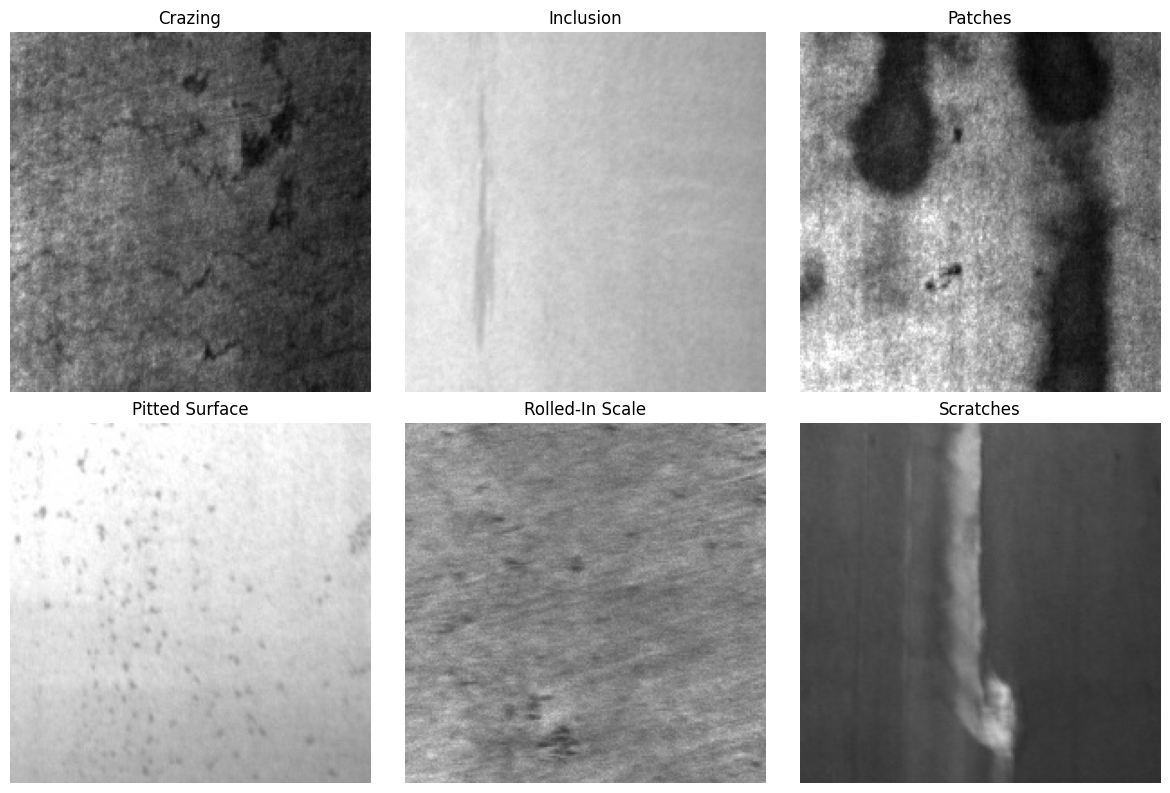

In [14]:
import matplotlib.pyplot as plt
from PIL import Image
import random

class_names = [
    "crazing",
    "inclusion",
    "patches",
    "pitted_surface",
    "rolled-in_scale",
    "scratches"
]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, class_name in zip(axes.flatten(), class_names):

    class_images = [
        file for file in train_image_files
        if get_primary_class(file) == class_name
    ]

    sample_image = random.choice(class_images)

    image = Image.open(sample_image)

    ax.imshow(image, cmap="gray")
    ax.set_title(class_name.replace("_", " ").title())
    ax.axis("off")

plt.tight_layout()
plt.show()

In [15]:
sample = Image.open(train_image_files[0])

print("Example file:", train_image_files[0].name)
print("Image size:", sample.size)
print("Image mode:", sample.mode)

Example file: crazing_1.jpg
Image size: (200, 200)
Image mode: RGB


In [16]:
from collections import Counter

all_images = train_image_files + val_image_files

sizes = Counter()
modes = Counter()

for image_path in all_images:
    with Image.open(image_path) as img:
        sizes[img.size] += 1
        modes[img.mode] += 1

print("IMAGE SIZES")
for size, count in sizes.items():
    print(size, ":", count)

print("\nIMAGE MODES")
for mode, count in modes.items():
    print(mode, ":", count)

IMAGE SIZES
(200, 200) : 1800

IMAGE MODES
RGB : 1800


In [17]:
import torch
import torchvision

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

print("CUDA available:", torch.cuda.is_available())

PyTorch version: 2.4.1+cpu
Torchvision version: 0.19.1+cpu
CUDA available: False


In [18]:
from torchvision import transforms

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [19]:
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset

class_names = [
    "crazing",
    "inclusion",
    "patches",
    "pitted_surface",
    "rolled-in_scale",
    "scratches"
]

class_to_idx = {
    class_name: idx 
    for idx, class_name in enumerate(class_names)
}

print(class_to_idx)

{'crazing': 0, 'inclusion': 1, 'patches': 2, 'pitted_surface': 3, 'rolled-in_scale': 4, 'scratches': 5}


In [20]:
class SteelDefectDataset(Dataset):

    def __init__(self, image_files, transform=None):
        self.image_files = image_files
        self.transform = transform

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):

        image_path = self.image_files[idx]

        image = Image.open(image_path).convert("RGB")

        label_name = None

        for class_name in class_names:
            if image_path.stem.startswith(class_name + "_"):
                label_name = class_name
                break

        if label_name is None:
            raise ValueError(
                f"Could not determine class for {image_path.name}"
            )

        label = class_to_idx[label_name]

        if self.transform:
            image = self.transform(image)

        return image, label

In [21]:
train_dataset = SteelDefectDataset(
    train_image_files,
    transform=train_transform
)

val_dataset = SteelDefectDataset(
    val_image_files,
    transform=val_transform
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))

Training samples: 1440
Validation samples: 360


In [22]:
import torch

print("PyTorch:", torch.__version__)
print(torch.rand(2, 2))

PyTorch: 2.4.1+cpu
tensor([[0.7381, 0.4251],
        [0.6898, 0.0558]])


In [23]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size = 32,
    shuffle = True
)

val_loader = DataLoader(
    val_dataset,
    batch_size = 32,
    shuffle = False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 45
Validation batches: 12


In [24]:
images, labels = next(iter(train_loader))

print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)
print("First 10 labels:", labels[:10])

Batch image shape: torch.Size([32, 3, 224, 224])
Batch label shape: torch.Size([32])
First 10 labels: tensor([2, 4, 4, 2, 3, 2, 5, 3, 1, 5])


In [25]:
import torch
import torch.nn as nn 
import torch.nn.functional as F

In [26]:
class SimpleCNN(nn.Module):

    def __init__(self, num_classes=6):
        super(SimpleCNN, self).__init__()

        self.conv1 = nn.Conv2d(
            in_channels=3,
            out_channels=16,
            kernel_size=3,
            padding=1
        )

        self.conv2 = nn.Conv2d(
            in_channels=16,
            out_channels=32,
            kernel_size=3,
            padding=1
        )

        self.conv3 = nn.Conv2d(
            in_channels=32,
            out_channels=64,
            kernel_size=3,
            padding=1
        )

        self.pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )

        self.fc1 = nn.Linear(
            64 * 28 * 28,
            128
        )

        self.fc2 = nn.Linear(
            128,
            num_classes
        )

        self.dropout = nn.Dropout(0.5)

    def forward(self, x):

        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))

        x = torch.flatten(x, 1)

        x = F.relu(self.fc1(x))
        x = self.dropout(x)

        x = self.fc2(x)

        return x

In [27]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = SimpleCNN(
    num_classes=len(class_names)
)

model = model.to(device)

print("Device:", device)
print(model)

Device: cpu
SimpleCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=50176, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=6, bias=True)
  (dropout): Dropout(p=0.5, inplace=False)
)


In [28]:
images, labels = next(iter(train_loader))
images = images.to(device)
labels = labels.to(device)
outputs = model(images)
print("Input batch shape:", images.shape)
print("Output shape:", outputs.shape)
print("Labels shape:", labels.shape)

Input batch shape: torch.Size([32, 3, 224, 224])
Output shape: torch.Size([32, 6])
Labels shape: torch.Size([32])


In [29]:
criterion = nn.CrossEntropyLoss()
print(criterion)

CrossEntropyLoss()


In [30]:
import torch.optim as optim

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)
print(optimizer)

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [31]:
loss = criterion(outputs, labels)
print("Initial loss:", loss.item())

Initial loss: 1.7907335758209229


In [32]:
def train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    device,
    epochs=2
):

    for epoch in range(epochs):

        # TRAINING
        model.train()

        train_loss = 0.0
        train_correct = 0
        train_total = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            train_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            train_total += labels.size(0)
            train_correct += (predicted == labels).sum().item()


        average_train_loss = train_loss / len(train_loader)
        train_accuracy = 100 * train_correct / train_total


        # VALIDATION
        model.eval()

        val_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():

            for images, labels in val_loader:

                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)

                loss = criterion(outputs, labels)

                val_loss += loss.item()

                _, predicted = torch.max(outputs, 1)

                val_total += labels.size(0)
                val_correct += (predicted == labels).sum().item()


        average_val_loss = val_loss / len(val_loader)
        val_accuracy = 100 * val_correct / val_total


        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Train Loss: {average_train_loss:.4f} "
            f"Train Acc: {train_accuracy:.2f}% "
            f"Val Loss: {average_val_loss:.4f} "
            f"Val Acc: {val_accuracy:.2f}%"
        )

In [33]:
train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    device,
    epochs=2
)

Epoch [1/2] Train Loss: 1.3719 Train Acc: 44.79% Val Loss: 1.3405 Val Acc: 38.89%
Epoch [2/2] Train Loss: 0.7513 Train Acc: 74.10% Val Loss: 1.1494 Val Acc: 58.33%


In [34]:
model.eval()

with torch.no_grad():

    images, labels = next(iter(val_loader))

    images = images.to(device)
    labels = labels.to(device)

    outputs = model(images)

    test_loss = criterion(outputs, labels)

    print("Output minimum:", outputs.min().item())
    print("Output maximum:", outputs.max().item())
    print("Current batch loss:", test_loss.item())

Output minimum: -13.462024688720703
Output maximum: 13.369451522827148
Current batch loss: 0.05485863983631134


In [35]:
model.eval()

total_val_loss = 0
total_correct = 0
total_samples = 0

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        loss = criterion(outputs, labels)

        total_val_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total_samples += labels.size(0)
        total_correct += (predicted == labels).sum().item()


average_val_loss = total_val_loss / len(val_loader)

val_accuracy = 100 * total_correct / total_samples


print("Average validation loss:", average_val_loss)
print("Validation accuracy:", val_accuracy)

Average validation loss: 1.1494010798633099
Validation accuracy: 58.333333333333336


In [36]:
model = SimpleCNN(
    num_classes = len(class_names)
).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

In [37]:
history = train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    device,
    epochs=5
)

Epoch [1/5] Train Loss: 1.3365 Train Acc: 50.00% Val Loss: 1.3869 Val Acc: 52.78%
Epoch [2/5] Train Loss: 0.8715 Train Acc: 70.14% Val Loss: 1.0625 Val Acc: 59.72%
Epoch [3/5] Train Loss: 0.6275 Train Acc: 79.17% Val Loss: 0.8781 Val Acc: 71.67%
Epoch [4/5] Train Loss: 0.4195 Train Acc: 87.15% Val Loss: 0.6166 Val Acc: 78.06%
Epoch [5/5] Train Loss: 0.3698 Train Acc: 87.92% Val Loss: 0.8734 Val Acc: 74.44%


In [38]:
history = {
    "train_loss": [1.4446, 0.7917, 0.6239, 0.4683, 0.4422],
    "val_loss": [1.3887, 0.9428, 0.9073, 0.5382, 0.7621],
    "train_acc": [45.35, 72.78, 76.94, 83.61, 85.00],
    "val_acc": [58.33, 60.00, 62.22, 80.00, 72.22]
}

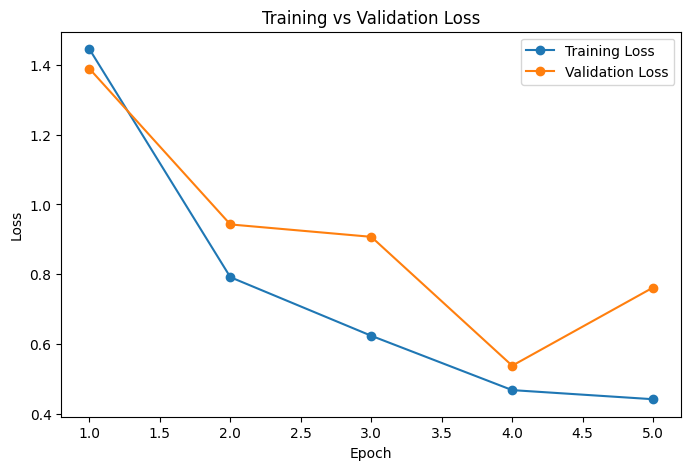

In [39]:
import matplotlib.pyplot as plt
epochs = range(1, len(history["train_loss"]) +1)
plt.figure(figsize=(8,5))
plt.plot(epochs, history["train_loss"], marker = "o", label="Training Loss")
plt.plot(epochs, history["val_loss"], marker = "o", label = "Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.show()

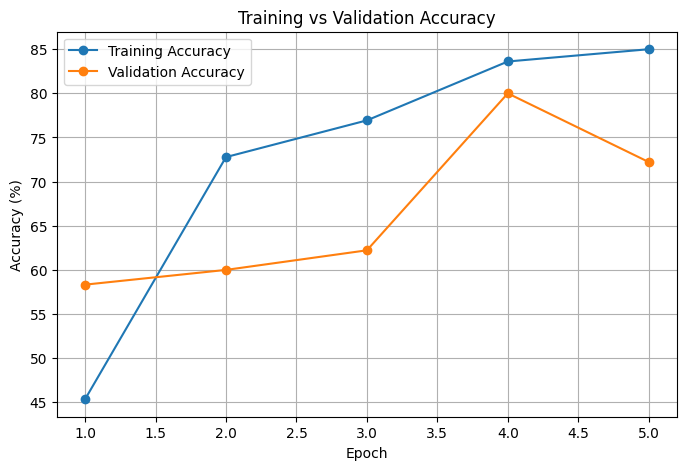

In [40]:
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history["train_acc"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs,
    history["val_acc"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid()

plt.show()

In [41]:
model = SimpleCNN(
    num_classes=len(class_names)
).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

In [42]:
import torch

def train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    device,
    epochs=10,
    save_path="../models/simple_cnn_best.pth"
):

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }

    best_val_accuracy = 0.0

    for epoch in range(epochs):

        # -------------------------
        # TRAINING
        # -------------------------
        model.train()

        train_loss = 0.0
        train_correct = 0
        train_total = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            train_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            train_total += labels.size(0)
            train_correct += (predicted == labels).sum().item()

        avg_train_loss = train_loss / len(train_loader)
        train_accuracy = 100 * train_correct / train_total


        # -------------------------
        # VALIDATION
        # -------------------------
        model.eval()

        val_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():

            for images, labels in val_loader:

                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss += loss.item()

                _, predicted = torch.max(outputs, 1)

                val_total += labels.size(0)
                val_correct += (predicted == labels).sum().item()

        avg_val_loss = val_loss / len(val_loader)
        val_accuracy = 100 * val_correct / val_total


        # -------------------------
        # SAVE HISTORY
        # -------------------------
        history["train_loss"].append(avg_train_loss)
        history["val_loss"].append(avg_val_loss)
        history["train_acc"].append(train_accuracy)
        history["val_acc"].append(val_accuracy)


        # -------------------------
        # SAVE BEST MODEL
        # -------------------------
        if val_accuracy > best_val_accuracy:

            best_val_accuracy = val_accuracy

            torch.save(
                model.state_dict(),
                save_path
            )

            print(
                f"Best model saved! "
                f"Validation Accuracy: {best_val_accuracy:.2f}%"
            )


        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Train Loss: {avg_train_loss:.4f} "
            f"Train Acc: {train_accuracy:.2f}% "
            f"Val Loss: {avg_val_loss:.4f} "
            f"Val Acc: {val_accuracy:.2f}%"
        )

    return history

In [43]:
history = train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    device,
    epochs=10
)

Best model saved! Validation Accuracy: 58.33%
Epoch [1/10] Train Loss: 1.3065 Train Acc: 48.68% Val Loss: 1.1275 Val Acc: 58.33%
Best model saved! Validation Accuracy: 64.17%
Epoch [2/10] Train Loss: 0.6998 Train Acc: 75.14% Val Loss: 0.7700 Val Acc: 64.17%
Best model saved! Validation Accuracy: 78.06%
Epoch [3/10] Train Loss: 0.4648 Train Acc: 83.68% Val Loss: 0.5540 Val Acc: 78.06%
Best model saved! Validation Accuracy: 87.50%
Epoch [4/10] Train Loss: 0.4318 Train Acc: 85.21% Val Loss: 0.4107 Val Acc: 87.50%
Epoch [5/10] Train Loss: 0.3403 Train Acc: 89.38% Val Loss: 0.5119 Val Acc: 82.50%
Best model saved! Validation Accuracy: 88.06%
Epoch [6/10] Train Loss: 0.2714 Train Acc: 91.53% Val Loss: 0.3009 Val Acc: 88.06%
Epoch [7/10] Train Loss: 0.2594 Train Acc: 92.99% Val Loss: 0.3371 Val Acc: 88.06%
Epoch [8/10] Train Loss: 0.2594 Train Acc: 91.94% Val Loss: 0.3091 Val Acc: 86.94%
Best model saved! Validation Accuracy: 89.44%
Epoch [9/10] Train Loss: 0.2624 Train Acc: 92.01% Val Loss: 

In [44]:
best_model = SimpleCNN(
    num_classes=len(class_names)
).to(device)

best_model.load_state_dict(
    torch.load(
        "../models/simple_cnn_best.pth",
        map_location=device
    )
)

best_model.eval()

print("Best CNN loaded successfully")

Best CNN loaded successfully


C:\Users\swanz\AppData\Local\Temp\ipykernel_4100\1577488801.py:6: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  torch.load(


In [45]:
correct = 0
total = 0

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = best_model(images)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total

print(f"Best CNN Validation Accuracy: {accuracy:.2f}%")

Best CNN Validation Accuracy: 90.56%


In [46]:
best_model = SimpleCNN(
    num_classes = len(class_names)
).to(device)

best_model.load_state_dict(
    torch.load(
        "../models/simple_cnn_best.pth",
        map_location = device
    )
)

best_model.eval()
print("Best CNN loaded successfully")

Best CNN loaded successfully


C:\Users\swanz\AppData\Local\Temp\ipykernel_4100\3557992913.py:6: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  torch.load(


In [47]:
all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in val_loader:

        images = images.to(device)
        labels = labels.to(device)
        outputs = best_model(images)
        _, predicted = torch.max(outputs.data, 1)
        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predicted.cpu().numpy())

In [48]:
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt

cm = confusion_matrix(all_labels, all_predictions)
print(cm)


[[60  0  0  0  0  0]
 [ 0 36  0 17  0  7]
 [ 0  0 60  0  0  0]
 [ 0  2  2 51  0  5]
 [ 0  0  0  0 60  0]
 [ 0  1  0  0  0 59]]


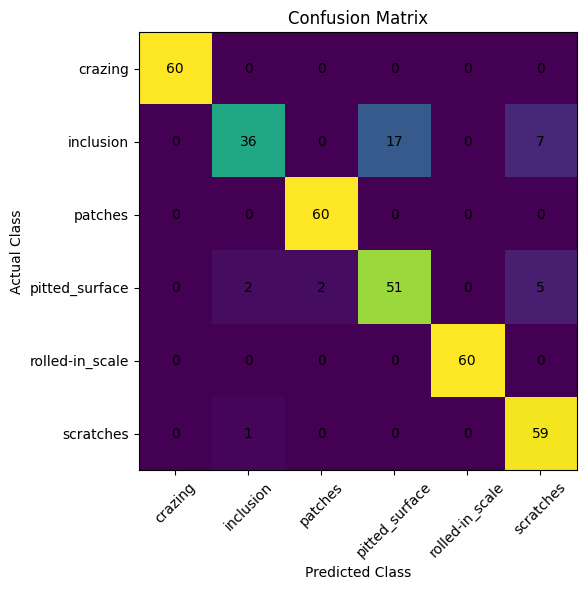

In [49]:
plt.figure(figsize=(8,6))
plt.imshow(cm)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(
    range(len(class_names)),
    class_names,
    rotation=45
)

plt.yticks(
    range(len(class_names)),
    class_names
)

for i in range(len(class_names)):
    for j in range(len(class_names)):
        plt.text(
            j,
            i,
            cm[i,j],
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

In [50]:
print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=class_names
    )
)

                 precision    recall  f1-score   support

        crazing       1.00      1.00      1.00        60
      inclusion       0.92      0.60      0.73        60
        patches       0.97      1.00      0.98        60
 pitted_surface       0.75      0.85      0.80        60
rolled-in_scale       1.00      1.00      1.00        60
      scratches       0.83      0.98      0.90        60

       accuracy                           0.91       360
      macro avg       0.91      0.91      0.90       360
   weighted avg       0.91      0.91      0.90       360



In [51]:
import torch
import torch.nn as nn 
from torchvision import models
from torchvision.models import ResNet18_Weights

In [52]:
weights = ResNet18_Weights.DEFAULT
resnet_model = models.resnet18(
    weights = weights
)

print(resnet_model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [53]:
for param in resnet_model.parameters():
    param.requires_grad = False

In [54]:
num_features = resnet_model.fc.in_features
print("Features entering final layer:", num_features)

Features entering final layer: 512


In [55]:
resnet_model.fc = nn.Linear(
    num_features,
    len(class_names)
)

In [56]:
resnet_model = resnet_model.to(device)
print("Device:", device)
print(resnet_model.fc)

Device: cpu
Linear(in_features=512, out_features=6, bias=True)


In [57]:
trainable_parameters = [
    name
    for name, param in resnet_model.named_parameters()
    if param.requires_grad
]

print("trainable_parameters:")

for name in trainable_parameters:
    print(name)

trainable_parameters:
fc.weight
fc.bias


In [58]:
images, labels = next(iter(train_loader))
images = images.to(device)
outputs = resnet_model(images)
print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

Input shape: torch.Size([32, 3, 224, 224])
Output shape: torch.Size([32, 6])


In [59]:
criterion_resnet = nn.CrossEntropyLoss()
optimizer_resnet = torch.optim.Adam(
    resnet_model.fc.parameters(),
    lr=0.001
)

In [60]:
history_resnet = train_model(
    resnet_model,
    train_loader,
    val_loader,
    criterion_resnet,
    optimizer_resnet,
    device,
    epochs=5,
    save_path="../models/resnet18_stage1_best.pth"
)

Best model saved! Validation Accuracy: 77.78%
Epoch [1/5] Train Loss: 1.0325 Train Acc: 71.60% Val Loss: 0.8202 Val Acc: 77.78%
Best model saved! Validation Accuracy: 90.00%
Epoch [2/5] Train Loss: 0.3804 Train Acc: 94.44% Val Loss: 0.4032 Val Acc: 90.00%
Epoch [3/5] Train Loss: 0.2468 Train Acc: 96.11% Val Loss: 0.3446 Val Acc: 89.17%
Best model saved! Validation Accuracy: 93.33%
Epoch [4/5] Train Loss: 0.1912 Train Acc: 96.88% Val Loss: 0.2687 Val Acc: 93.33%
Epoch [5/5] Train Loss: 0.1617 Train Acc: 97.36% Val Loss: 0.2569 Val Acc: 92.78%


In [61]:
best_resnet = models.resnet18(weights=ResNet18_Weights.DEFAULT)

num_features = best_resnet.fc.in_features

best_resnet.fc = nn.Linear(
    num_features,
    len(class_names)
)

best_resnet.load_state_dict(
    torch.load(
        "../models/resnet18_stage1_best.pth",
        map_location=device
    )
)

best_resnet = best_resnet.to(device)
best_resnet.eval()

print("Best ResNet loaded successfully")

Best ResNet loaded successfully


C:\Users\swanz\AppData\Local\Temp\ipykernel_4100\1356399195.py:11: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  torch.load(


In [62]:
all_labels_resnet = []
all_predictions_resnet = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = best_resnet(images)

        _, predicted = torch.max(outputs, 1)

        all_labels_resnet.extend(labels.cpu().numpy())
        all_predictions_resnet.extend(predicted.cpu().numpy())

In [63]:
from sklearn.metrics import confusion_matrix, classification_report
cm_resnet =  confusion_matrix(
    all_labels_resnet,
    all_predictions_resnet
)

print(cm_resnet)

print(
    classification_report(
        all_labels_resnet,
        all_predictions_resnet,
        target_names=class_names
    )
)

[[60  0  0  0  0  0]
 [ 0 44  0 12  0  4]
 [ 0  0 60  0  0  0]
 [ 2  0  0 58  0  0]
 [ 3  0  2  0 55  0]
 [ 0  0  1  0  0 59]]
                 precision    recall  f1-score   support

        crazing       0.92      1.00      0.96        60
      inclusion       1.00      0.73      0.85        60
        patches       0.95      1.00      0.98        60
 pitted_surface       0.83      0.97      0.89        60
rolled-in_scale       1.00      0.92      0.96        60
      scratches       0.94      0.98      0.96        60

       accuracy                           0.93       360
      macro avg       0.94      0.93      0.93       360
   weighted avg       0.94      0.93      0.93       360



In [64]:
for param in best_resnet.parameters():
    param.requires_grad = False

In [65]:
for param in best_resnet.layer4.parameters():
    param.requires_grad = True

In [66]:
for param in best_resnet.fc.parameters():
    param.requires_grad = True

In [67]:
print("Trainable parameters:")
for name, param in best_resnet.named_parameters():
    if param.requires_grad:
        print(name)

Trainable parameters:
layer4.0.conv1.weight
layer4.0.bn1.weight
layer4.0.bn1.bias
layer4.0.conv2.weight
layer4.0.bn2.weight
layer4.0.bn2.bias
layer4.0.downsample.0.weight
layer4.0.downsample.1.weight
layer4.0.downsample.1.bias
layer4.1.conv1.weight
layer4.1.bn1.weight
layer4.1.bn1.bias
layer4.1.conv2.weight
layer4.1.bn2.weight
layer4.1.bn2.bias
fc.weight
fc.bias


In [68]:
optimizer_finetune = torch.optim.Adam(
    filter(
        lambda p: p.requires_grad,
        best_resnet.parameters()
    ),
    lr = 0.0001
)

In [69]:
criterion_finetune = nn.CrossEntropyLoss()

In [70]:
history_finetune = train_model(
    best_resnet,
    train_loader,
    val_loader,
    criterion_finetune,
    optimizer_finetune,
    device,
    epochs=5,
    save_path= "../models/resnet18_finetuned_best.pth"
)

Best model saved! Validation Accuracy: 97.50%
Epoch [1/5] Train Loss: 0.0874 Train Acc: 97.29% Val Loss: 0.0543 Val Acc: 97.50%
Best model saved! Validation Accuracy: 99.17%
Epoch [2/5] Train Loss: 0.0236 Train Acc: 99.17% Val Loss: 0.0268 Val Acc: 99.17%
Best model saved! Validation Accuracy: 100.00%
Epoch [3/5] Train Loss: 0.0066 Train Acc: 99.93% Val Loss: 0.0056 Val Acc: 100.00%
Epoch [4/5] Train Loss: 0.0128 Train Acc: 99.58% Val Loss: 0.0075 Val Acc: 99.72%
Epoch [5/5] Train Loss: 0.0061 Train Acc: 99.79% Val Loss: 0.0053 Val Acc: 100.00%


In [71]:
fine_model = models.resnet18(
    weights=ResNet18_Weights.DEFAULT
)

num_features = fine_model.fc.in_features

fine_model.fc = nn.Linear(
    num_features,
    len(class_names)
)

fine_model.load_state_dict(
    torch.load(
        "../models/resnet18_finetuned_best.pth",
        map_location=device
    )
)

fine_model = fine_model.to(device)
fine_model.eval()

print("Best fine-tuned ResNet loaded")

Best fine-tuned ResNet loaded


C:\Users\swanz\AppData\Local\Temp\ipykernel_4100\3948546073.py:13: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  torch.load(


In [72]:
fine_labels = []
fine_predictions = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = fine_model(images)

        _, predicted = torch.max(outputs,1)
        fine_labels.extend(labels.cpu().numpy())
        fine_predictions.extend(predicted.cpu().numpy())

In [73]:
from sklearn.metrics import confusion_matrix, classification_report

cm_fine = confusion_matrix(
    fine_labels,
    fine_predictions
)

print(cm_fine)

print(
    classification_report(
        fine_labels,
        fine_predictions,
        target_names=class_names
    )
)

[[60  0  0  0  0  0]
 [ 0 60  0  0  0  0]
 [ 0  0 60  0  0  0]
 [ 0  0  0 60  0  0]
 [ 0  0  0  0 60  0]
 [ 0  0  0  0  0 60]]
                 precision    recall  f1-score   support

        crazing       1.00      1.00      1.00        60
      inclusion       1.00      1.00      1.00        60
        patches       1.00      1.00      1.00        60
 pitted_surface       1.00      1.00      1.00        60
rolled-in_scale       1.00      1.00      1.00        60
      scratches       1.00      1.00      1.00        60

       accuracy                           1.00       360
      macro avg       1.00      1.00      1.00       360
   weighted avg       1.00      1.00      1.00       360



In [74]:
import hashlib

def image_hash(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

train_hashes = {
    image_hash(path): path 
    for path in train_image_files
}

val_hashes =  {
    image_hash(path): path 
    for path in val_image_files
}

duplicate_hashes = set(train_hashes.keys()) & set(val_hashes.keys())

print(
    "Exact duplicate images across train and validation:",
    len(duplicate_hashes)
)

Exact duplicate images across train and validation: 0


In [75]:
from sklearn.metrics import confusion_matrix, classification_report

cm_fine = confusion_matrix(
    fine_labels,
    fine_predictions
)

print(cm_fine)

print(
    classification_report(
        fine_labels,
        fine_predictions,
        target_names=class_names
    )
)

[[60  0  0  0  0  0]
 [ 0 60  0  0  0  0]
 [ 0  0 60  0  0  0]
 [ 0  0  0 60  0  0]
 [ 0  0  0  0 60  0]
 [ 0  0  0  0  0 60]]
                 precision    recall  f1-score   support

        crazing       1.00      1.00      1.00        60
      inclusion       1.00      1.00      1.00        60
        patches       1.00      1.00      1.00        60
 pitted_surface       1.00      1.00      1.00        60
rolled-in_scale       1.00      1.00      1.00        60
      scratches       1.00      1.00      1.00        60

       accuracy                           1.00       360
      macro avg       1.00      1.00      1.00       360
   weighted avg       1.00      1.00      1.00       360



In [76]:
all_images_files = train_image_files + val_image_files
print("Total images:", len(all_images_files))

Total images: 1800


In [77]:
def get_primary_class(image_path):
    for class_name in class_names:
        if image_path.stem.startswith(class_name + "_"):
            return class_name

    raise ValueError(
        f"Could not determine class for {image_path.name}" 
    )

all_labels = [
    get_primary_class(path)
    for path in all_images_files
]

print("Images:", len(all_images_files))
print("Labels:", len(all_labels))

Images: 1800
Labels: 1800


In [78]:
from sklearn.model_selection import train_test_split

train_files_final, temp_files, train_labels_final, temp_labels = train_test_split(
    all_images_files,
    all_labels,
    test_size=0.30,
    random_state=42,
    stratify=all_labels
)

val_files_final, test_files_final, val_labels_final,test_labels_final= train_test_split(
    temp_files,
    temp_labels,
    test_size=0.50,
    random_state=42,
    stratify=temp_labels
)

print("Training:", len(train_files_final))
print("Validation:", len(val_files_final))
print("Test:", len(test_files_final))

Training: 1260
Validation: 270
Test: 270


In [79]:
from collections import Counter

print("TRAIN")
print(Counter(train_labels_final))

print("\nVALIDATION")
print(Counter(val_labels_final))

print("\nTEST")
print(Counter(test_labels_final))

TRAIN
Counter({'scratches': 210, 'patches': 210, 'crazing': 210, 'inclusion': 210, 'pitted_surface': 210, 'rolled-in_scale': 210})

VALIDATION
Counter({'scratches': 45, 'rolled-in_scale': 45, 'patches': 45, 'inclusion': 45, 'pitted_surface': 45, 'crazing': 45})

TEST
Counter({'patches': 45, 'inclusion': 45, 'pitted_surface': 45, 'scratches': 45, 'rolled-in_scale': 45, 'crazing': 45})


In [80]:
import pandas as pd

split_rows = []

for path, label in zip(train_files_final, train_labels_final):
    split_rows.append({
        "filepath": str(path),
        "label": label,
        "split": "train"
    })

for path, label in zip(val_files_final, val_labels_final):
    split_rows.append({
        "filepath": str(path),
        "label": label,
        "split": "validation"
    })

for path, label in zip(test_files_final, test_labels_final):
    split_rows.append({
        "filepath": str(path),
        "label": label,
        "split": "test"
    })

splits_df = pd.DataFrame(split_rows)

splits_df.to_csv(
    "../data/final_splits.csv",
    index=False
)

splits_df.head()

,filepath,label,split
0,..\data\train\images\scratches\scratches_111.jpg,scratches,train
1,..\data\train\images\scratches\scratches_68.jpg,scratches,train
2,..\data\train\images\patches\patches_164.jpg,patches,train
3,..\data\train\images\crazing\crazing_169.jpg,crazing,train
4,..\data\train\images\scratches\scratches_158.jpg,scratches,train


In [82]:
all_image_files = train_image_files + val_image_files 
print("Total images: ", len(all_image_files))

Total images:  1800


In [84]:
def get_primary_class(image_path):
    for class_name in class_names:
        if image_path.stem.startswith(class_name + "_"):
            return class_name

    raise ValueError(
    f"Could not determine class for {image_path.name}"
)

all_labels = [
    get_primary_class(path)
    for path in all_image_files
]

print("Images:", len(all_image_files))
print("Lables:", len(all_labels))

Images: 1800
Lables: 1800


In [85]:
from sklearn.model_selection import train_test_split

train_files_final, temp_files, train_labels_final, temp_labels = train_test_split(
    all_image_files,
    all_labels,
    test_size=0.30,
    random_state=42,
    stratify=all_labels
)

val_files_final, test_files_final, val_labels_final, test_labels_final = train_test_split(
    temp_files,
    temp_labels,
    test_size=0.50,
    random_state=42,
    stratify=temp_labels
)

print("Training:", len(train_files_final))
print("Validation:", len(val_files_final))
print("Test:", len(test_files_final))

Training: 1260
Validation: 270
Test: 270


In [88]:
from collections import Counter

print("TRAIN")
print(Counter(train_labels_final))

print("\nVALIDATION")
print(Counter(val_labels_final))

print("\nTEST")
print(Counter(test_labels_final))

TRAIN
Counter({'scratches': 210, 'patches': 210, 'crazing': 210, 'inclusion': 210, 'pitted_surface': 210, 'rolled-in_scale': 210})

VALIDATION
Counter({'scratches': 45, 'rolled-in_scale': 45, 'patches': 45, 'inclusion': 45, 'pitted_surface': 45, 'crazing': 45})

TEST
Counter({'patches': 45, 'inclusion': 45, 'pitted_surface': 45, 'scratches': 45, 'rolled-in_scale': 45, 'crazing': 45})


In [93]:
import pandas as pd 

split_rows = []

for path, label in zip(train_files_final, train_labels_final):
    split_rows.append({
    "filepath": str(path),
    "label": label,
    "split": "train"
    })

for path, label in zip(val_files_final, val_labels_final):
    split_rows.append({
        "filepath": str(path),
        "label": label,
        "split": "validation"
    })

for path, label in zip(test_files_final, test_labels_final):
    split_rows.append({
        "filepath": str(path),
        "label": label,
        "split": "test"
    })

split_df = pd.DataFrame(split_rows)

splits_df.to_csv(
    "../data/final_split.csv",
    index=False   
)

splits_df.head()

,filepath,label,split
0,..\data\train\images\scratches\scratches_111.jpg,scratches,train
1,..\data\train\images\scratches\scratches_68.jpg,scratches,train
2,..\data\train\images\patches\patches_164.jpg,patches,train
3,..\data\train\images\crazing\crazing_169.jpg,crazing,train
4,..\data\train\images\scratches\scratches_158.jpg,scratches,train


In [94]:
train_dataset_final = SteelDefectDataset(
    train_files_final,
    transform=train_transform
)

val_dataset_final = SteelDefectDataset(
    val_files_final,
    transform=val_transform
)

test_dataset_final = SteelDefectDataset(
    test_files_final,
    transform=val_transform
)

print("Training samples:", len(train_dataset_final))
print("Validation samples:", len(val_dataset_final))
print("Test samples:", len(test_dataset_final))

Training samples: 1260
Validation samples: 270
Test samples: 270


In [95]:
from torch.utils.data import DataLoader

train_loader_final = DataLoader(
    train_dataset_final,
    batch_size=32,
    shuffle=True
)

val_loader_final = DataLoader(
    val_dataset_final,
    batch_size=32,
    shuffle=False
)

test_loader_final = DataLoader(
    test_dataset_final,
    batch_size=32,
    shuffle=False
)

print("Training batches:", len(train_loader_final))
print("Validation batches:", len(val_loader_final))
print("Test batches:", len(test_loader_final))

Training batches: 40
Validation batches: 9
Test batches: 9


In [97]:
from torchvision import models
from torchvision.models import ResNet18_Weights
import torch.nn as nn

weights = ResNet18_Weights.DEFAULT

final_resnet = models.resnet18(
    weights = weights
)

num_features = final_resnet.fc.in_features

final_resnet.fc = nn.Linear(
    num_features,
    len(class_name)
)

final_resnet = final_resnet.to(device)
print(final_resnet.fc)

Linear(in_features=512, out_features=9, bias=True)


In [98]:
for param in final_resnet.parameters():
    param.requires_grad = False
for param in final_resnet.fc.parameters():
    param.requires_grad = True

In [100]:
criterion_final_stage1 = nn.CrossEntropyLoss()

optimizer_final_stage1 = torch.optim.Adam(
    final_resnet.fc.parameters(),
    lr=0.001
)

In [101]:
history_final_stage1 = train_model(
    final_resnet,
    train_loader_final,
    val_loader_final,
    criterion_final_stage1,
    optimizer_final_stage1,
    device,
    epochs=5,
    save_path="../models/final_resnet18_stage1_best.pth"
)

Best model saved! Validation Accuracy: 80.37%
Epoch [1/5] Train Loss: 1.1164 Train Acc: 68.17% Val Loss: 0.8918 Val Acc: 80.37%
Best model saved! Validation Accuracy: 94.81%
Epoch [2/5] Train Loss: 0.4454 Train Acc: 93.17% Val Loss: 0.3294 Val Acc: 94.81%
Epoch [3/5] Train Loss: 0.2952 Train Acc: 95.63% Val Loss: 0.2486 Val Acc: 94.44%
Best model saved! Validation Accuracy: 96.30%
Epoch [4/5] Train Loss: 0.2138 Train Acc: 96.27% Val Loss: 0.1713 Val Acc: 96.30%
Epoch [5/5] Train Loss: 0.1776 Train Acc: 97.14% Val Loss: 0.1522 Val Acc: 96.30%


In [112]:
final_finetune = models.resnet18(
    weights = ResNet18_Weights.DEFAULT
)

num_features = final_finetune.fc.in_features

final_finetune.fc = nn.Linear(
    num_features,
    len(class_names)
)

final_finetune.load_state_dict(
    torch.load(
        "../models/final_resnet18_stage1_best.pth",
        map_location=device
    )
)

final_finetune = final_finetune.to(device)
print("Best Stage-1 model loaded")

Best Stage-1 model loaded


C:\Users\swanz\AppData\Local\Temp\ipykernel_4100\2101344897.py:13: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  torch.load(


In [114]:
for param in final_finetune.parameters():
    param.requires_grad = False

for param in final_finetune.layer4.parameters():
    param.requires_grad = True

for param in final_finetune.fc.parameters():
    param.requires_grad = True

In [115]:
for name, param in final_finetune.named_parameters():
    if param.requires_grad:
        print(name)

layer4.0.conv1.weight
layer4.0.bn1.weight
layer4.0.bn1.bias
layer4.0.conv2.weight
layer4.0.bn2.weight
layer4.0.bn2.bias
layer4.0.downsample.0.weight
layer4.0.downsample.1.weight
layer4.0.downsample.1.bias
layer4.1.conv1.weight
layer4.1.bn1.weight
layer4.1.bn1.bias
layer4.1.conv2.weight
layer4.1.bn2.weight
layer4.1.bn2.bias
fc.weight
fc.bias


In [116]:
criterion_final_finetune = nn.CrossEntropyLoss()

optimizer_final_finetune = torch.optim.Adam(
    filter(
        lambda p: p.requires_grad,
        final_finetune.parameters()
    ),
    lr=0.0001
)

In [117]:
history_final_finetune = train_model(
    final_finetune,
    train_loader_final,
    val_loader_final,
    criterion_final_finetune,
    optimizer_final_finetune,
    device,
    epochs=5,
    save_path="../models/final_resnet18_finetuned_best.pth"
)

Best model saved! Validation Accuracy: 98.89%
Epoch [1/5] Train Loss: 0.0631 Train Acc: 98.57% Val Loss: 0.0248 Val Acc: 98.89%
Best model saved! Validation Accuracy: 99.26%
Epoch [2/5] Train Loss: 0.0238 Train Acc: 99.44% Val Loss: 0.0137 Val Acc: 99.26%
Best model saved! Validation Accuracy: 100.00%
Epoch [3/5] Train Loss: 0.0102 Train Acc: 99.76% Val Loss: 0.0028 Val Acc: 100.00%
Epoch [4/5] Train Loss: 0.0303 Train Acc: 99.13% Val Loss: 0.0173 Val Acc: 99.26%
Epoch [5/5] Train Loss: 0.0151 Train Acc: 99.44% Val Loss: 0.0147 Val Acc: 99.26%


In [118]:
final_model = models.resnet18(
    weights = ResNet18_Weights.DEFAULT
)

num_features = final_model.fc.in_features

final_model.fc = nn.Linear(
    num_features,
    len(class_names)
)

final_model.load_state_dict(
    torch.load(
        "../models/final_resnet18_finetuned_best.pth",
        map_location=device
    )
)

final_model = final_model.to(device)
final_model.eval()

print("Final model loaded successfully")

Final model loaded successfully


C:\Users\swanz\AppData\Local\Temp\ipykernel_4100\3485569310.py:13: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  torch.load(


In [17]:
final_model.eval()

y_true_test = []
y_pred_test = []

final_test_loss = 0.0
final_test_correct = 0
final_test_total = 0

with torch.no_grad():

    for images, labels in test_loader_final:

        images = images.to(device)
        labels = labels.to(device)

        outputs = final_model(images)

        loss = criterion_final_finetune(
            outputs,
            labels
        )

        final_test_loss += loss.item()

        _, predicted = torch.max(
            outputs,
            dim=1
        )

        final_test_total += labels.size(0)

        final_test_correct += (
            predicted == labels
        ).sum().item()

        y_true_test.extend(
            labels.cpu().tolist()
        )

        y_pred_test.extend(
            predicted.cpu().tolist()
        )


average_test_loss = (
    final_test_loss / len(test_loader_final)
)

final_test_accuracy = (
    100 * final_test_correct / final_test_total
)

print("Number of true labels:", len(y_true_test))
print("Number of predictions:", len(y_pred_test))

print(
    f"Final Test Loss: {average_test_loss:.4f}"
)

print(
    f"Final Test Accuracy: {final_test_accuracy:.2f}%"
)

NameError: name 'test_loader_final' is not defined

In [124]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

cm_test = confusion_matrix(
    y_true_test,
    y_pred_test
)

print(cm_test)

[[45  0  0  0  0  0]
 [ 0 45  0  0  0  0]
 [ 0  0 45  0  0  0]
 [ 0  0  0 45  0  0]
 [ 0  0  0  0 45  0]
 [ 0  0  0  0  0 45]]


In [125]:
print(
    classification_report(
        y_true_test,
        y_pred_test,
        target_names=class_names,
        digits=4
    )
)

                 precision    recall  f1-score   support

        crazing     1.0000    1.0000    1.0000        45
      inclusion     1.0000    1.0000    1.0000        45
        patches     1.0000    1.0000    1.0000        45
 pitted_surface     1.0000    1.0000    1.0000        45
rolled-in_scale     1.0000    1.0000    1.0000        45
      scratches     1.0000    1.0000    1.0000        45

       accuracy                         1.0000       270
      macro avg     1.0000    1.0000    1.0000       270
   weighted avg     1.0000    1.0000    1.0000       270



In [1]:
activations = None
gradients = None

In [2]:
def forward_hook(module, input, output):
    global activations
    activations = output

def backward_hook(module, grad_input, grad_output):
    global gradients
    gradients = grad_output[0]
    

In [9]:
import torch
import torch.nn as nn
from torchvision import models, transforms
from torchvision.models import ResNet18_Weights
from PIL import Image
from pathlib import Path

In [10]:
class_names = [
    "crazing",
    "inclusion",
    "patches",
    "pitted_surface",
    "rolled-in_scale",
    "scratches"
]

In [11]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(device)

cpu


In [12]:
val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [13]:
final_model = models.resnet18(
    weights=ResNet18_Weights.DEFAULT
)

num_features = final_model.fc.in_features

final_model.fc = nn.Linear(
    num_features,
    len(class_names)
)

final_model.load_state_dict(
    torch.load(
        "../models/final_resnet18_finetuned_best.pth",
        map_location=device
    )
)

final_model = final_model.to(device)
final_model.eval()

print("Final model loaded successfully")

Final model loaded successfully


C:\Users\swanz\AppData\Local\Temp\ipykernel_4632\3331581840.py:13: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  torch.load(


In [14]:
target_layer = final_model.layer4[-1].conv2

In [15]:
forward_handle = target_layer.register_forward_hook(
    forward_hook
)

backward_handle = target_layer.register_full_backward_hook(
    backward_hook
)

print("Grad-CAM hooks attached")

Grad-CAM hooks attached


In [18]:
import pandas as pd
from pathlib import Path

splits_df = pd.read_csv(
    "../data/final_splits.csv"
)

test_df = splits_df[
    splits_df["split"] == "test"
].reset_index(drop=True)

print("Test images:", len(test_df))

Test images: 270


In [20]:
sample_path = Path(
    test_df.loc[0, "filepath"]
)

actual_class = test_df.loc[0, "label"]

print("Image:", sample_path.name)
print("Actual class:", actual_class)
print("File exists:", sample_path.exists())

Image: patches_264.jpg
Actual class: patches
File exists: True


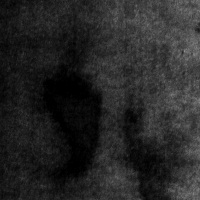

In [21]:
original_image = Image.open(
    sample_path
).convert("RGB")

original_image

In [22]:
input_tensor = val_transform(
    original_image
).unsqueeze(0)

input_tensor = input_tensor.to(device)

print(input_tensor.shape)

torch.Size([1, 3, 224, 224])


In [24]:
final_model.zero_grad()
outputs = final_model(input_tensor)
predicted_index = outputs.argmax(dim=1).item()
predicted_class = class_names[predicted_index]
probabilities = torch.softmax(outputs, dim=1)
confidence = probabilities[0, predicted_index].item()
print("Predicted class:", predicted_class)
print(f"Confidence: {confidence * 100:.2f}%")

Predicted class: patches
Confidence: 99.95%


In [25]:
score = outputs[0, predicted_index]
score.backward()

In [28]:
import torch.nn.functional as F

weights = gradients.mean(
    dim=(2,3),
    keepdim = True
)

cam = (
    weights * activations
).sum(
    dim=1,
    keepdim=True
)

cam = F.relu(cam)

cam = F.interpolate(
    cam,
    size=(224,224),
    mode="bilinear",
    align_corners=False
)

cam = cam.squeeze()

cam = cam - cam.min()
cam = cam / (cam.max() + 1e-8)

gradcam = cam.detach().cpu().numpy()
print("Grad-CAM shape:", gradcam.shape)

Grad-CAM shape: (224, 224)


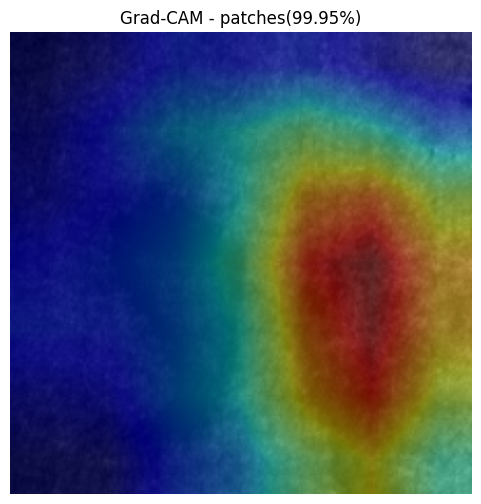

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))

plt.imshow(
    original_image.resize((224,224))
)

plt.imshow(
    gradcam,
    cmap="jet",
    alpha=0.45
)

plt.title(
    f"Grad-CAM - {predicted_class}({confidence * 100:.2f}%)"
)

plt.axis("off")
plt.show()

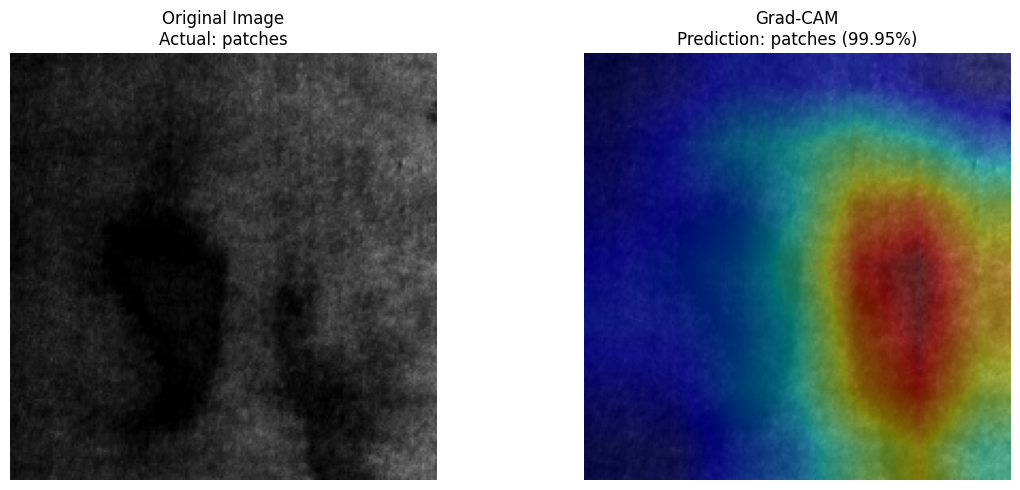

In [30]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.imshow(original_image)
plt.title(f"Original Image\nActual: {actual_class}")
plt.axis("off")


plt.subplot(1, 2, 2)

plt.imshow(
    original_image.resize((224, 224))
)

plt.imshow(
    gradcam,
    cmap="jet",
    alpha=0.45
)

plt.title(
    f"Grad-CAM\nPrediction: {predicted_class} ({confidence * 100:.2f}%)"
)

plt.axis("off")

plt.tight_layout()
plt.show()

In [37]:
def generate_gradcam(
    model,
    image_path,
    transform,
    class_names,
    device,
    target_layer
):

    activations_store = {}
    gradients_store = {}

    def forward_hook(module, input, output):
        activations_store["value"] = output

    def backward_hook(module, grad_input, grad_output):
        gradients_store["value"] = grad_output[0]

    forward_handle = target_layer.register_forward_hook(
        forward_hook
    )

    backward_handle = target_layer.register_full_backward_hook(
        backward_hook
    )

    image = Image.open(image_path).convert("RGB")

    input_tensor = transform(image).unsqueeze(0).to(device)

    model.zero_grad()

    outputs = model(input_tensor)

    predicted_index = outputs.argmax(dim=1).item()
    predicted_class = class_names[predicted_index]

    probabilities = torch.softmax(outputs, dim=1)

    confidence = probabilities[
        0,
        predicted_index
    ].item()

    score = outputs[0, predicted_index]

    score.backward()

    activations = activations_store["value"]
    gradients = gradients_store["value"]

    weights = gradients.mean(
        dim=(2, 3),
        keepdim=True
    )

    cam = (
        weights * activations
    ).sum(
        dim=1,
        keepdim=True
    )

    cam = F.relu(cam)

    cam = F.interpolate(
        cam,
        size=(224, 224),
        mode="bilinear",
        align_corners=False
    )

    cam = cam.squeeze()

    cam = cam - cam.min()
    cam = cam / (cam.max() + 1e-8)

    gradcam = cam.detach().cpu().numpy()

    forward_handle.remove()
    backward_handle.remove()

    return image, predicted_class, confidence, gradcam

In [38]:
target_layer = final_model.layer4[-1].conv2

image, prediction, confidence, gradcam = generate_gradcam(
    final_model,
    sample_path,
    val_transform,
    class_names,
    device,
    target_layer
)

print("Prediction:", prediction)
print(f"Confidence: {confidence * 100:.2f}%")

Prediction: patches
Confidence: 99.95%


In [41]:
sample_paths = {}

for class_name in class_names:
    class_rows = test_df[test_df["label"] == class_name]

    sample_paths[class_name] = Path(
        class_rows.iloc[0]["filepath"]
    )

print(sample_paths)

{'crazing': WindowsPath('../data/train/images/crazing/crazing_139.jpg'), 'inclusion': WindowsPath('../data/train/images/inclusion/inclusion_201.jpg'), 'patches': WindowsPath('../data/validation/images/patches/patches_264.jpg'), 'pitted_surface': WindowsPath('../data/train/images/pitted_surface/pitted_surface_156.jpg'), 'rolled-in_scale': WindowsPath('../data/train/images/rolled-in_scale/rolled-in_scale_234.jpg'), 'scratches': WindowsPath('../data/train/images/scratches/scratches_141.jpg')}


In [42]:
results = []

target_layer = final_model.layer4[-1].conv2

for class_name, image_path in sample_paths.items():

    image, prediction, confidence, gradcam = generate_gradcam(
        final_model,
        image_path,
        val_transform,
        class_names,
        device,
        target_layer
    )

    results.append(
        (
            class_name,
            image,
            prediction,
            confidence,
            gradcam
        )
    )

    print(
        f"Actual: {class_name} | "
        f"Predicted: {prediction} | "
        f"Confidence: {confidence * 100:.2f}%"
    )

Actual: crazing | Predicted: crazing | Confidence: 100.00%
Actual: inclusion | Predicted: inclusion | Confidence: 99.95%
Actual: patches | Predicted: patches | Confidence: 99.95%
Actual: pitted_surface | Predicted: pitted_surface | Confidence: 100.00%
Actual: rolled-in_scale | Predicted: rolled-in_scale | Confidence: 100.00%
Actual: scratches | Predicted: scratches | Confidence: 98.72%


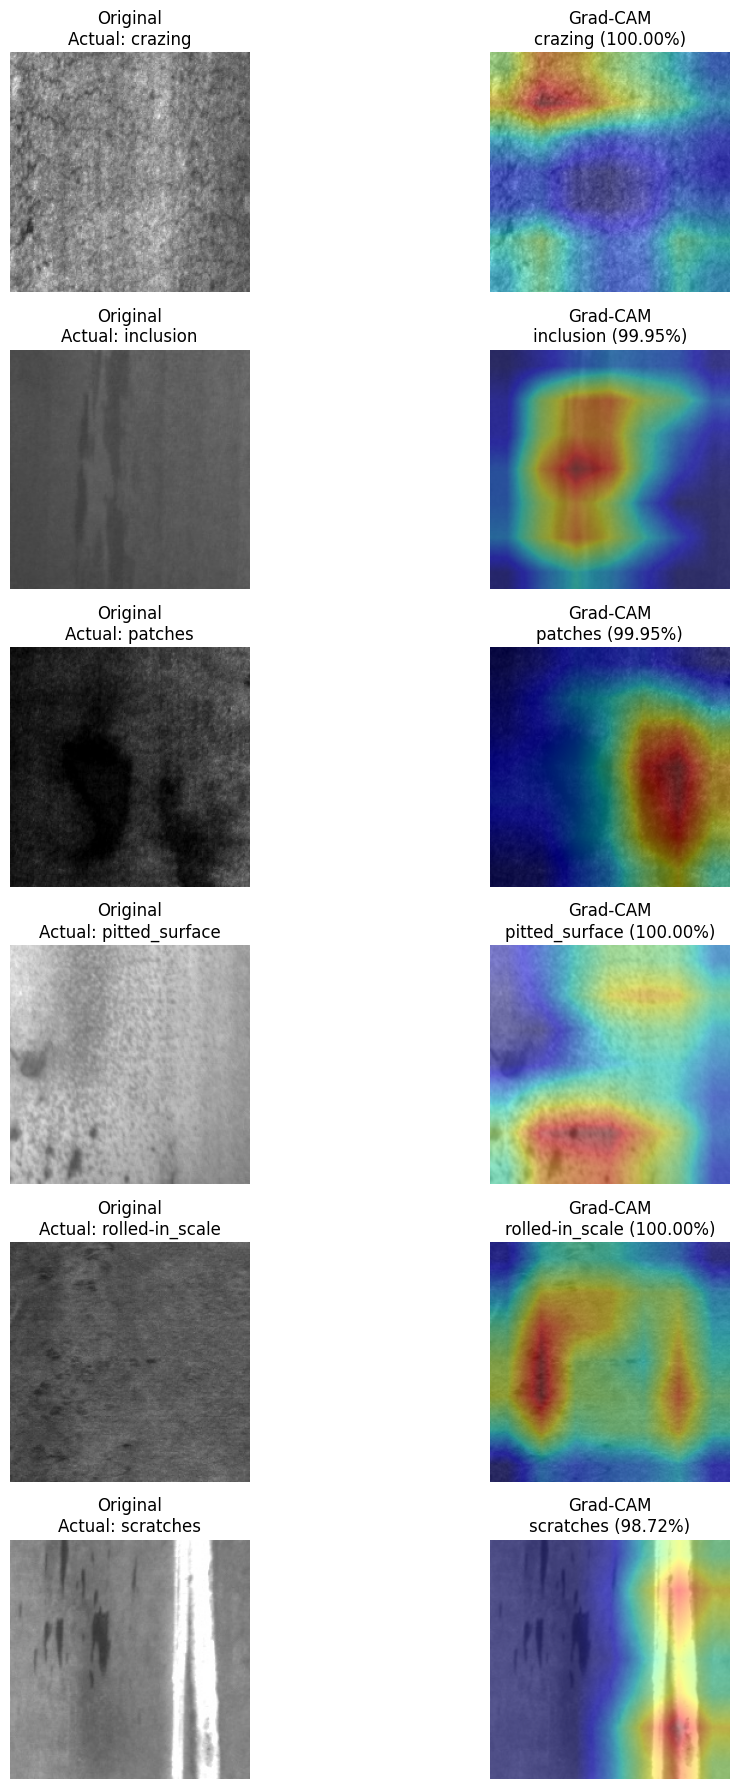

In [ ]:
plt.figure(figsize=(12, 18))

for i, (
    actual,
    image,
    prediction,
    confidence,
    gradcam
) in enumerate(results):

    plt.subplot(6, 2, i * 2 + 1)

    plt.imshow(image)
    plt.title(f"Original\nActual: {actual}")
    plt.axis("off")


    plt.subplot(6, 2, i * 2 + 2)

    plt.imshow(
        image.resize((224, 224))
    )

    plt.imshow(
        gradcam,
        cmap="jet",
        alpha=0.45
    )

    plt.title(
        f"Grad-CAM\n"
        f"{prediction} ({confidence * 100:.2f}%)"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()